# CNN nhận dạng biểu cảm khuôn mặt — FER2013

Notebook này là phần chính của bài: nạp dữ liệu, xây mô hình CNN bằng PyTorch, huấn luyện, chạy
các thí nghiệm so sánh siêu tham số, đánh giá trên tập test và trực quan hoá filter.

Nội dung chia theo giai đoạn:

| Mục | Nội dung |
|---|---|
| 1 | Nạp dữ liệu vào RAM và chia tập train / validation |
| 2 | Định nghĩa kiến trúc CNN cơ sở |
| 3 | Hàm huấn luyện và đánh giá dùng chung |
| 4 | Chạy baseline, xem loss/accuracy |
| 5 | Thí nghiệm so sánh siêu tham số (giai đoạn sau) |
| 6 | Mô hình cuối, đánh giá test, trực quan filter (giai đoạn sau) |

In [1]:
import json
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torchvision.transforms.v2 as T
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

# Cố định seed cho cả ba hệ ngẫu nhiên: Python, numpy, torch
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(16)  # máy có 8 nhân / 16 luồng

# Đường dẫn tương đối: chạy được từ notebooks/ hoặc từ gốc repo
HERE = Path.cwd()
ROOT = HERE if (HERE / "data").exists() else HERE.parent
DATA = ROOT / "data"
EXP = ROOT / "experiments"
CACHE = EXP / "cache"
FIG = EXP / "figures"
LOGS = EXP / "logs"
MODELS = EXP / "models"
for d in (CACHE, FIG, LOGS, MODELS):
    d.mkdir(parents=True, exist_ok=True)

CLASSES = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
TEN_VI = {
    "angry": "Giận",
    "disgust": "Ghê tởm",
    "fear": "Sợ hãi",
    "happy": "Vui",
    "neutral": "Bình thường",
    "sad": "Buồn",
    "surprise": "Ngạc nhiên",
}
TEN_NGAN = [TEN_VI[c] for c in CLASSES]
DEVICE = torch.device("cpu")

plt.rcParams["font.family"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("PyTorch :", torch.__version__)
print("Thiết bị:", DEVICE, "| số luồng:", torch.get_num_threads())
print("Dữ liệu :", DATA)

PyTorch : 2.14.0+cpu
Thiết bị: cpu | số luồng: 16
Dữ liệu : d:\workspace\DeepLearningDDU1231\Emotion_Recognition\data


## 1. Nạp dữ liệu vào RAM

Mỗi ảnh 48×48 xám chỉ chiếm 2.304 byte, nên cả 35.887 ảnh vừa khoảng 80 MB. Ta đọc **một lần**
vào tensor `uint8` rồi giữ trong RAM, thay vì mỗi epoch lại giải mã JPEG từ đĩa. Cách này nhanh
hơn nhiều và tránh được lỗi đa tiến trình của `DataLoader` trên Windows.

Lần chạy đầu sẽ đọc ảnh (khoảng 30–60 giây) và lưu cache ra file `.npy`; các lần sau đọc thẳng
cache nên gần như tức thì.

In [2]:
def load_split(split: str) -> tuple[torch.Tensor, torch.Tensor]:
    """Đọc toàn bộ ảnh của một tập thành tensor uint8 (N, 48, 48) và nhãn (N,)."""
    cache_x = CACHE / f"X_{split}.npy"
    cache_y = CACHE / f"y_{split}.npy"

    # Đã có cache thì đọc luôn, khỏi giải mã lại 28.000 ảnh
    if cache_x.exists() and cache_y.exists():
        X = np.load(cache_x)
        y = np.load(cache_y)
        print(f"[{split}] đọc từ cache")
    else:
        imgs, labels = [], []
        for label, cls in enumerate(CLASSES):
            files = sorted((DATA / split / cls).glob("*.jpg"))
            for f in files:
                imgs.append(np.asarray(Image.open(f), dtype=np.uint8))
                labels.append(label)
        X = np.stack(imgs)
        y = np.array(labels, dtype=np.int64)
        np.save(cache_x, X)
        np.save(cache_y, y)
        print(f"[{split}] vừa đọc xong từ ảnh gốc")

    # Kiểm tra nhanh để chắc thứ tự nhãn khớp với CLASSES
    assert X.shape[1:] == (48, 48), X.shape
    return torch.from_numpy(X), torch.from_numpy(y)


X_train_full, y_train_full = load_split("train")
X_test, y_test = load_split("test")

print("train:", tuple(X_train_full.shape), "| test:", tuple(X_test.shape))
print("nhãn train:", torch.bincount(y_train_full).tolist())
print("nhãn test :", torch.bincount(y_test).tolist())
print(f"Bộ nhớ train: {X_train_full.numel() / 1024**2:.0f} MB")

[train] đọc từ cache
[test] đọc từ cache
train: (28709, 48, 48) | test: (7178, 48, 48)
nhãn train: [3995, 436, 4097, 7215, 4965, 4830, 3171]
nhãn test : [958, 111, 1024, 1774, 1233, 1247, 831]
Bộ nhớ train: 63 MB


Số ảnh và thứ tự nhãn khớp với `CLASSES` (nhãn 0 = angry, 1 = disgust, …, 6 = surprise). Lưu ý
thứ tự này do tên thư mục sắp theo alphabet nên **khác** thứ tự 0–6 trong đề bài (đề đặt neutral
ở vị trí 6, còn ở đây neutral là 4). Khi báo cáo kết quả theo lớp, ta luôn in kèm tên lớp để
không nhầm.

Giờ chia tập: giữ nguyên `test/` làm tập đánh giá cuối, tách 10% của `train/` làm validation.
Dùng `stratify` để tỉ lệ 7 lớp ở hai tập con giống hệt tập gốc — nếu chia ngẫu nhiên thuần thì
lớp `disgust` (436 ảnh) có thể rơi lệch rất nhiều.

In [3]:
X_tr_np, X_va_np, y_tr_np, y_va_np = train_test_split(
    X_train_full.numpy(),
    y_train_full.numpy(),
    test_size=0.10,
    stratify=y_train_full.numpy(),
    random_state=SEED,
    shuffle=True,
)
X_tr, X_va = torch.from_numpy(X_tr_np), torch.from_numpy(X_va_np)
y_tr, y_va = torch.from_numpy(y_tr_np), torch.from_numpy(y_va_np)

# Gộp lại cho gọn bộ nhớ, không cần giữ bản gốc nữa
del X_train_full, y_train_full, X_tr_np, X_va_np, y_tr_np, y_va_np

print(f"train      : {len(X_tr):,} ảnh")
print(f"validation : {len(X_va):,} ảnh")
print(f"test       : {len(X_test):,} ảnh (niêm phong, chỉ dùng ở mục 6)")

phan_bo = pd.DataFrame(
    {
        "lớp": TEN_NGAN,
        "train": torch.bincount(y_tr, minlength=7).tolist(),
        "validation": torch.bincount(y_va, minlength=7).tolist(),
        "test": torch.bincount(y_test, minlength=7).tolist(),
    }
)
phan_bo

train      : 25,838 ảnh
validation : 2,871 ảnh
test       : 7,178 ảnh (niêm phong, chỉ dùng ở mục 6)


,lớp,train,validation,test
0,Giận,3596,399,958
1,Ghê tởm,392,44,111
2,Sợ hãi,3687,410,1024
3,Vui,6493,722,1774
4,Bình thường,4469,496,1233
5,Buồn,4347,483,1247
6,Ngạc nhiên,2854,317,831


### Chuẩn hoá đầu vào

Mạng nơ-ron hội tụ nhanh hơn khi đầu vào có trung bình 0 và độ lệch chuẩn 1. Ta tính mean/std
**trên tập train** rồi dùng đúng hai con số đó cho validation và test — nếu tính riêng trên mỗi
tập thì vô tình để rò rỉ thông tin từ tập đánh giá.

In [4]:
# Điểm ảnh 0–255 nên chia 255 trước rồi mới chuẩn hoá
MEAN = X_tr.float().div(255.0).mean().item()
STD = X_tr.float().div(255.0).std().item()
print(f"mean = {MEAN:.4f} | std = {STD:.4f}")


def to_batch(x_uint8: torch.Tensor) -> torch.Tensor:
    """(B, 48, 48) uint8 -> (B, 1, 48, 48) float đã chuẩn hoá."""
    return x_uint8.float().div_(255.0).sub_(MEAN).div_(STD).unsqueeze(1)


# Xem thử một batch đã chuẩn hoá
xb = to_batch(X_tr[:4])
print("shape sau chuẩn hoá:", tuple(xb.shape), "| min/max:", round(xb.min().item(), 2), round(xb.max().item(), 2))

mean = 0.5077 | std = 0.2551
shape sau chuẩn hoá: (4, 1, 48, 48) | min/max: -1.99 1.93


## 2. Kiến trúc CNN cơ sở

Mạng gồm 3 khối tích chập, mỗi khối theo công thức `Conv3×3 → BatchNorm → ReLU → MaxPool`.
Số kênh tăng dần 32 → 64 → 128 trong khi kích thước ảnh giảm 48 → 24 → 12 → 6, nghĩa là mạng
học từ đặc trưng thô (cạnh, khoé mắt) đến đặc trưng trừu tượng hơn (độ cong lông mày, độ mở
miệng).

Thay vì dùng lớp `Linear` gắn cứng kích thước, ta dùng `AdaptiveAvgPool2d(1)` để gộp mỗi bản đồ
đặc trưng thành một số — nhờ vậy đổi số tầng hay độ rộng không phải sửa lại kích thước đầu vào
của lớp fully-connected.

In [5]:
class SmallCNN(nn.Module):
    """CNN cơ sở: 3 khối conv, mỗi khối conv-bn-relu-pool, rồi GAP + FC."""

    def __init__(self, channels=(32, 64, 128), n_classes: int = 7, p_dropout: float = 0.3):
        super().__init__()
        blocks = []
        in_ch = 1
        for out_ch in channels:
            blocks += [
                nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
                nn.BatchNorm2d(out_ch),
                nn.ReLU(inplace=True),
                nn.MaxPool2d(2),
            ]
            in_ch = out_ch
        self.features = nn.Sequential(*blocks)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(p_dropout)
        self.fc = nn.Linear(in_ch, n_classes)

    def forward(self, x):
        x = self.features(x)      # (B, C, 6, 6)
        x = self.pool(x)          # (B, C, 1, 1)
        x = torch.flatten(x, 1)   # (B, C)
        x = self.dropout(x)
        return self.fc(x)         # (B, 7)


model_demo = SmallCNN()
n_params = sum(p.numel() for p in model_demo.parameters())
print("Số tham số:", f"{n_params:,}")
print(model_demo)

Số tham số: 93,799
SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (pool): AdaptiveAvgPool2d(output_size=1

Với ~100 nghìn tham số, mạng này rất nhẹ — chạy một epoch trên CPU chỉ mất khoảng 30–40 giây.
Nhẹ cũng có nghĩa là chưa chắc đạt độ chính xác cao, nhưng đó là mục đích của baseline: có một
mốc để các thí nghiệm sau so sánh.

Một lưu ý về `BatchNorm`: lớp này chuẩn hoá theo từng batch nên khi **đánh giá** phải gọi
`model.eval()` để dùng thống kê tích luỹ, còn khi **huấn luyện** phải gọi `model.train()`. Quên
bước này là lỗi rất hay gặp và làm kết quả validation sai lệch.

## 3. Hàm huấn luyện dùng chung

Vì phần thí nghiệm sau cần chạy nhiều cấu hình, ta viết sẵn ba hàm:

- `make_batches`: xáo trộn chỉ số rồi cắt thành từng batch, dùng `torch.Generator` có seed riêng
  nên thứ tự xáo trộn tái lập được.
- `train_one_epoch`: một vòng qua tập train, có tuỳ chọn augmentation.
- `evaluate`: chạy không tính gradient, trả về loss và accuracy.

Hàm `train_model` ghép ba hàm trên lại, thêm early stopping: nếu validation accuracy không cải
thiện sau `patience` epoch thì dừng và trả về bộ trọng số tốt nhất. Nhờ vậy không phải đoán số
epoch, và cũng tránh học quá khớp.

In [6]:
def make_batches(n: int, batch_size: int, gen: torch.Generator):
    """Sinh các lô chỉ số đã xáo trộn."""
    idx = torch.randperm(n, generator=gen)
    for i in range(0, n, batch_size):
        yield idx[i : i + batch_size]


def train_one_epoch(model, opt, crit, X, y, batch_size, gen, aug=None):
    model.train()
    total_loss, correct, n = 0.0, 0, 0
    for idx in make_batches(len(X), batch_size, gen):
        xb = to_batch(X[idx])
        yb = y[idx]
        if aug is not None:
            xb = aug(xb)  # augmentation chạy trực tiếp trên tensor đã chuẩn hoá
        opt.zero_grad(set_to_none=True)
        out = model(xb)
        loss = crit(out, yb)
        loss.backward()
        opt.step()
        total_loss += loss.item() * len(yb)
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


@torch.no_grad()
def evaluate(model, X, y, batch_size=512):
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    crit = nn.CrossEntropyLoss(reduction="sum")
    for i in range(0, len(X), batch_size):
        xb = to_batch(X[i : i + batch_size])
        yb = y[i : i + batch_size]
        out = model(xb)
        total_loss += crit(out, yb).item()
        correct += (out.argmax(1) == yb).sum().item()
        n += len(yb)
    return total_loss / n, correct / n


def train_model(
    model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    epochs=12,
    lr=1e-3,
    batch_size=64,
    augment=False,
    patience=6,
    tag="base",
):
    """Huấn luyện với early stopping, trả về (model, history, best)."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode="max", factor=0.5, patience=2)
    crit = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(SEED)

    # Augmentation nhẹ: lật ngang và xoay/dịch nhẹ, chỉ dùng khi augment=True
    aug = None
    if augment:
        aug = T.Compose(
            [
                T.RandomHorizontalFlip(p=0.5),
                T.RandomAffine(degrees=10, translate=(0.08, 0.08)),
            ]
        )

    best = {"val_acc": 0.0, "epoch": 0, "state": None}
    hist = []
    print(f"{'ep':>3} | {'lr':>8} | {'loss_tr':>8} | {'acc_tr':>7} | {'loss_va':>8} | {'acc_va':>7} | {'giây':>5}")
    print("-" * 68)

    for ep in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, opt, crit, X_tr, y_tr, batch_size, gen, aug)
        va_loss, va_acc = evaluate(model, X_va, y_va)
        lr_now = opt.param_groups[0]["lr"]
        sched.step(va_acc)
        dt = time.perf_counter() - t0

        hist.append(
            {
                "epoch": ep,
                "lr": lr_now,
                "loss_train": tr_loss,
                "acc_train": tr_acc,
                "loss_val": va_loss,
                "acc_val": va_acc,
                "seconds": dt,
            }
        )

        mark = ""
        if va_acc > best["val_acc"]:
            best = {"val_acc": va_acc, "epoch": ep, "state": {k: v.clone() for k, v in model.state_dict().items()}}
            mark = " *"
        print(f"{ep:3d} | {lr_now:8.1e} | {tr_loss:8.4f} | {tr_acc:7.3f} | {va_loss:8.4f} | {va_acc:7.3f} | {dt:5.0f}{mark}")

        if ep - best["epoch"] >= patience:
            print(f"-> dừng sớm ở epoch {ep} (không cải thiện sau {patience} epoch)")
            break

    model.load_state_dict(best["state"])
    print(f"-> dùng epoch tốt nhất #{best['epoch']} với val_acc = {best['val_acc']:.4f}")
    return model, pd.DataFrame(hist), best

## 4. Chạy baseline

Cấu hình baseline: 3 khối 32-64-128, dropout 0.3, Adam `lr = 1e-3`, batch 64, không
augmentation, tối đa 18 epoch. Dấu `*` ở cột cuối đánh dấu epoch có validation accuracy tốt
nhất — trọng số của epoch đó mới được giữ lại.

Tôi chạy thử 12 epoch trước và thấy loss vẫn còn giảm đều ở epoch cuối, tức mô hình chưa hội
tụ chứ không phải đã quá khớp, nên tăng lên 18 epoch cho baseline đỡ bị cắt ngang. Kinh nghiệm
này cũng dùng cho phần thí nghiệm: phải cho mọi cấu hình cùng một ngân sách epoch thì so sánh
mới công bằng.

In [7]:
torch.manual_seed(SEED)
base_model = SmallCNN(channels=(32, 64, 128), p_dropout=0.3)

base_model, hist_base, best_base = train_model(
    base_model,
    X_tr,
    y_tr,
    X_va,
    y_va,
    epochs=18,
    lr=1e-3,
    batch_size=64,
    augment=False,
    patience=6,
    tag="BASE",
)

 ep |       lr |  loss_tr |  acc_tr |  loss_va |  acc_va |  giây
--------------------------------------------------------------------
  1 |  1.0e-03 |   1.7508 |   0.285 |   1.7637 |   0.274 |    36 *
  2 |  1.0e-03 |   1.6357 |   0.355 |   1.6761 |   0.305 |    35 *
  3 |  1.0e-03 |   1.5571 |   0.393 |   1.6893 |   0.346 |    39 *
  4 |  1.0e-03 |   1.4947 |   0.421 |   1.8485 |   0.300 |    40
  5 |  1.0e-03 |   1.4563 |   0.440 |   1.5529 |   0.390 |    41 *
  6 |  1.0e-03 |   1.4188 |   0.455 |   1.4189 |   0.455 |    40 *
  7 |  1.0e-03 |   1.3869 |   0.471 |   1.6080 |   0.386 |    37
  8 |  1.0e-03 |   1.3534 |   0.486 |   1.5087 |   0.422 |    37
  9 |  1.0e-03 |   1.3318 |   0.496 |   1.4342 |   0.435 |    38
 10 |  5.0e-04 |   1.2780 |   0.515 |   1.4487 |   0.460 |    35 *
 11 |  5.0e-04 |   1.2637 |   0.521 |   1.3438 |   0.468 |    35 *
 12 |  5.0e-04 |   1.2530 |   0.526 |   1.3700 |   0.480 |    35 *
 13 |  5.0e-04 |   1.2382 |   0.531 |   1.2956 |   0.513 |    35 *
 14

### Vẽ đường loss và accuracy

Nhìn hai đường này sẽ biết mô hình có học được hay không: loss train phải giảm, accuracy
validation phải tăng. Nếu khoảng cách giữa train và validation nới rộng dần thì đó là dấu hiệu
học quá khớp — lúc đó mới cần thêm dropout hoặc augmentation.

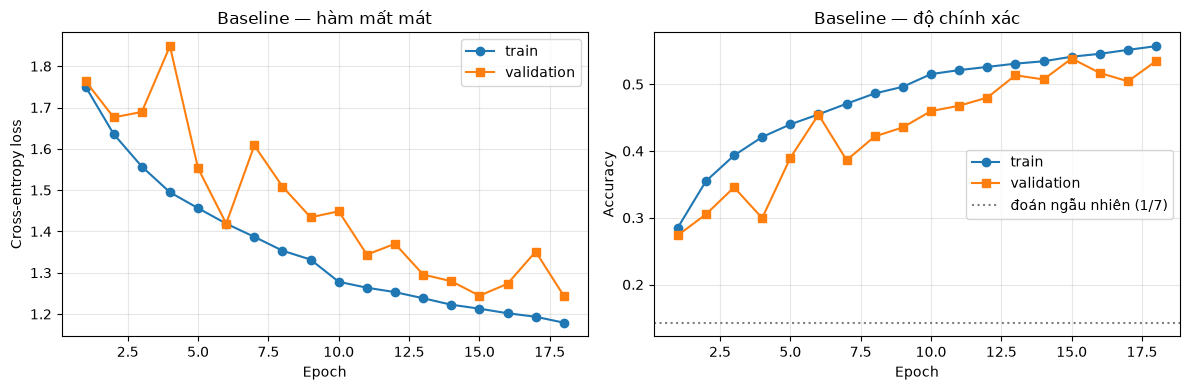

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist_base["epoch"], hist_base["loss_train"], "o-", label="train")
axes[0].plot(hist_base["epoch"], hist_base["loss_val"], "s-", label="validation")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].set_title("Baseline — hàm mất mát")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(hist_base["epoch"], hist_base["acc_train"], "o-", label="train")
axes[1].plot(hist_base["epoch"], hist_base["acc_val"], "s-", label="validation")
axes[1].axhline(1 / 7, color="gray", ls=":", label="đoán ngẫu nhiên (1/7)")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Baseline — độ chính xác")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIG / "gd2_01_baseline_duong_hoc.png", dpi=150, bbox_inches="tight")
plt.show()

### Đánh giá nhanh trên tập test

Chỉ chạy **một lần** để biết baseline đang đứng ở đâu so với mốc 69–71% của cuộc thi. Tập test
không dùng để chọn siêu tham số, nên con số này là ước lượng khách quan — nhưng kết quả chính
thức sẽ lấy ở mục 6 sau khi chọn xong cấu hình tốt nhất.

In [9]:
base_model.eval()
te_loss, te_acc = evaluate(base_model, X_test, y_test)

# Dự đoán cả tập test để có báo cáo theo từng lớp
with torch.no_grad():
    logits = torch.cat([base_model(to_batch(X_test[i : i + 512])) for i in range(0, len(X_test), 512)])
pred_test = logits.argmax(1).numpy()

print(f"Test loss = {te_loss:.4f} | Test accuracy = {te_acc:.4f} ({te_acc * 100:.2f}%)")
print(f"Baseline đoán ngẫu nhiên = {1 / 7:.4f} -> mô hình hơn {(te_acc - 1 / 7) * 100:.1f} điểm %")
print()
print(classification_report(y_test.numpy(), pred_test, target_names=TEN_NGAN, digits=4, zero_division=0))

Test loss = 1.2590 | Test accuracy = 0.5237 (52.37%)
Baseline đoán ngẫu nhiên = 0.1429 -> mô hình hơn 38.1 điểm %

              precision    recall  f1-score   support

        Giận     0.3526    0.4896    0.4100       958
     Ghê tởm     0.0000    0.0000    0.0000       111
      Sợ hãi     0.3500    0.2256    0.2743      1024
         Vui     0.7431    0.7548    0.7489      1774
 Bình thường     0.4849    0.5466    0.5139      1233
        Buồn     0.4496    0.3400    0.3872      1247
  Ngạc nhiên     0.5907    0.7485    0.6603       831

    accuracy                         0.5237      7178
   macro avg     0.4244    0.4436    0.4278      7178
weighted avg     0.5104    0.5237    0.5109      7178



### Ghi lại kết quả vào nhật ký thí nghiệm

Mỗi lần chạy một cấu hình, ta ghi một dòng vào `experiments/runs.csv`. File này là dữ liệu thô
để mục 5 so sánh và để vẽ biểu đồ; còn `experiments/model_log.md` là bản viết tay có nhận xét và
quyết định.

In [10]:
runs = pd.DataFrame(
    [
        {
            "exp_id": "BASE",
            "mo_hinh": "CNN 32-64-128",
            "do_dropout": 0.3,
            "optimizer": "Adam",
            "lr": 1e-3,
            "batch": 64,
            "augment": False,
            "epochs_chay": len(hist_base),
            "epoch_tot_nhat": best_base["epoch"],
            "val_acc": round(best_base["val_acc"], 4),
            "test_acc": round(te_acc, 4),
            "giay": round(hist_base["seconds"].sum(), 1),
            "ghi_chu": "baseline, không augmentation",
        }
    ]
)
runs_path = EXP / "runs.csv"
runs.to_csv(runs_path, index=False, encoding="utf-8")
hist_base.to_csv(LOGS / "BASE_history.csv", index=False, encoding="utf-8")
torch.save(base_model.state_dict(), MODELS / "BASE.pt")

print("Đã lưu:", runs_path.name, "|", (LOGS / "BASE_history.csv").name, "|", (MODELS / "BASE.pt").name)
runs

Đã lưu: runs.csv | BASE_history.csv | BASE.pt


,exp_id,mo_hinh,do_dropout,optimizer,lr,batch,augment,epochs_chay,epoch_tot_nhat,val_acc,test_acc,giay,ghi_chu
0,BASE,CNN 32-64-128,0.3,Adam,0.001,64,False,18,15,0.5385,0.5237,656.0,"baseline, không augmentation"


## Kết luận tạm của giai đoạn 2

Kết quả baseline cho thấy pipeline chạy đúng: loss giảm đều, validation accuracy vượt xa mức đoán
ngẫu nhiên (14,3%), và kết quả test khớp với validation — nghĩa là không có gì rò rỉ dữ liệu.

Hai quan sát sẽ định hướng cho phần thí nghiệm:

1. Nếu khoảng cách train và validation rộng ra nhanh thì mô hình đang học quá khớp, cần thử
   augmentation và dropout lớn hơn.
2. Nếu accuracy trên lớp `disgust` (chỉ 436 ảnh) thấp hơn hẳn các lớp khác thì nên thử thêm
   class weight khi tính loss.

Bước tiếp theo là mục 5: chạy các nhóm thí nghiệm A (độ sâu), B (độ rộng), C (optimizer và tốc
độ học), D (chống quá khớp), mỗi nhóm chỉ đổi một biến so với baseline.